# Εργασία 3 – Αξιολόγηση Μοντέλων

Στην εργασία προβλέπω πρώτα την κατηγορία έλλειψης ύπνου και έπειτα το σκορ κούρασης της επόμενης ημέρας. Συγκρίνω Extended Holdout, 5-Fold Cross-Validation και Nested Cross-Validation με K-Nearest Neighbors.

# Import Libraries

In [1]:
from pathlib import Path
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from scipy import stats

from sklearn.compose import ColumnTransformer
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    make_scorer,
    mean_absolute_error,
    mean_squared_error,
    precision_score,
    r2_score,
    recall_score,
)
from sklearn.model_selection import GridSearchCV, KFold, StratifiedKFold, train_test_split
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings('ignore')
get_ipython().run_line_magic('matplotlib', 'inline')
sns.set_theme(style='whitegrid')
pd.set_option('display.max_columns', 100)
pd.set_option('display.float_format', lambda x: f'{x:.4f}')

# Load Dataset

In [2]:
data_path = Path('sleep.csv')

if not data_path.exists():
    try:
        from google.colab import files
        uploaded = files.upload()
        data_path = Path('sleep.csv')
    except ImportError as exc:
        raise FileNotFoundError('Το sleep.csv πρέπει να βρίσκεται στον ίδιο φάκελο με το notebook.') from exc

df = pd.read_csv(data_path)
print('Διαστάσεις:', df.shape)
df.head()

Διαστάσεις: (8500, 18)


,user_id,age,gender,occupation_type,chronotype,bedtime_phone_minutes,primary_bedtime_app,screen_brightness_pct,blue_light_filter_active,caffeine_post_5pm_mg,physical_activity_min,sleep_latency_min,total_sleep_hours,deep_sleep_pct,rem_sleep_pct,morning_alarm_snoozes,next_day_fatigue_score,sleep_debt_category
0,USR-00001,29,Female,Healthcare / Shift Worker,Intermediate,179,Instagram / Reddit,54,1,0,21,84.4000,3.2000,23.5000,22.2000,7,10.0000,Severe Sleep Debt
1,USR-00002,58,Female,Student,Intermediate,163,YouTube,76,1,92,72,86.7000,4.0600,18.0000,21.5000,7,10.0000,Severe Sleep Debt
2,USR-00003,41,Female,Healthcare / Shift Worker,Night Owl,100,TikTok / Reels,59,0,45,23,70.5000,3.2000,18.1000,20.5000,7,10.0000,Severe Sleep Debt
3,USR-00004,36,Non-Binary,Remote Tech,Intermediate,34,YouTube,52,0,97,49,38.1000,6.9900,21.6000,22.4000,1,1.7000,Mild Deficit
4,USR-00005,23,Female,Healthcare / Shift Worker,Intermediate,27,TikTok / Reels,82,1,0,38,32.3000,4.5800,24.1000,22.8000,4,5.3000,Moderate Debt


In [3]:
print('Κενές τιμές:', int(df.isna().sum().sum()))
print('Διπλότυπες γραμμές:', int(df.duplicated().sum()))

pd.DataFrame({
    'Τύπος': df.dtypes.astype(str),
    'Μοναδικές τιμές': df.nunique(),
    'Κενές τιμές': df.isna().sum(),
})

Κενές τιμές: 0
Διπλότυπες γραμμές: 0


,Τύπος,Μοναδικές τιμές,Κενές τιμές
user_id,object,8500,0
age,int64,48,0
gender,object,3,0
occupation_type,object,5,0
chronotype,object,3,0
bedtime_phone_minutes,int64,179,0
primary_bedtime_app,object,6,0
screen_brightness_pct,int64,91,0
blue_light_filter_active,int64,2,0
caffeine_post_5pm_mg,int64,218,0


Το `user_id` είναι μοναδικό αναγνωριστικό και δεν περιγράφει συμπεριφορά ή συνήθεια ύπνου. Το αφαιρώ πριν από την εκπαίδευση, επειδή δεν αποτελεί χρήσιμο χαρακτηριστικό πρόβλεψης.

# Plot Variables

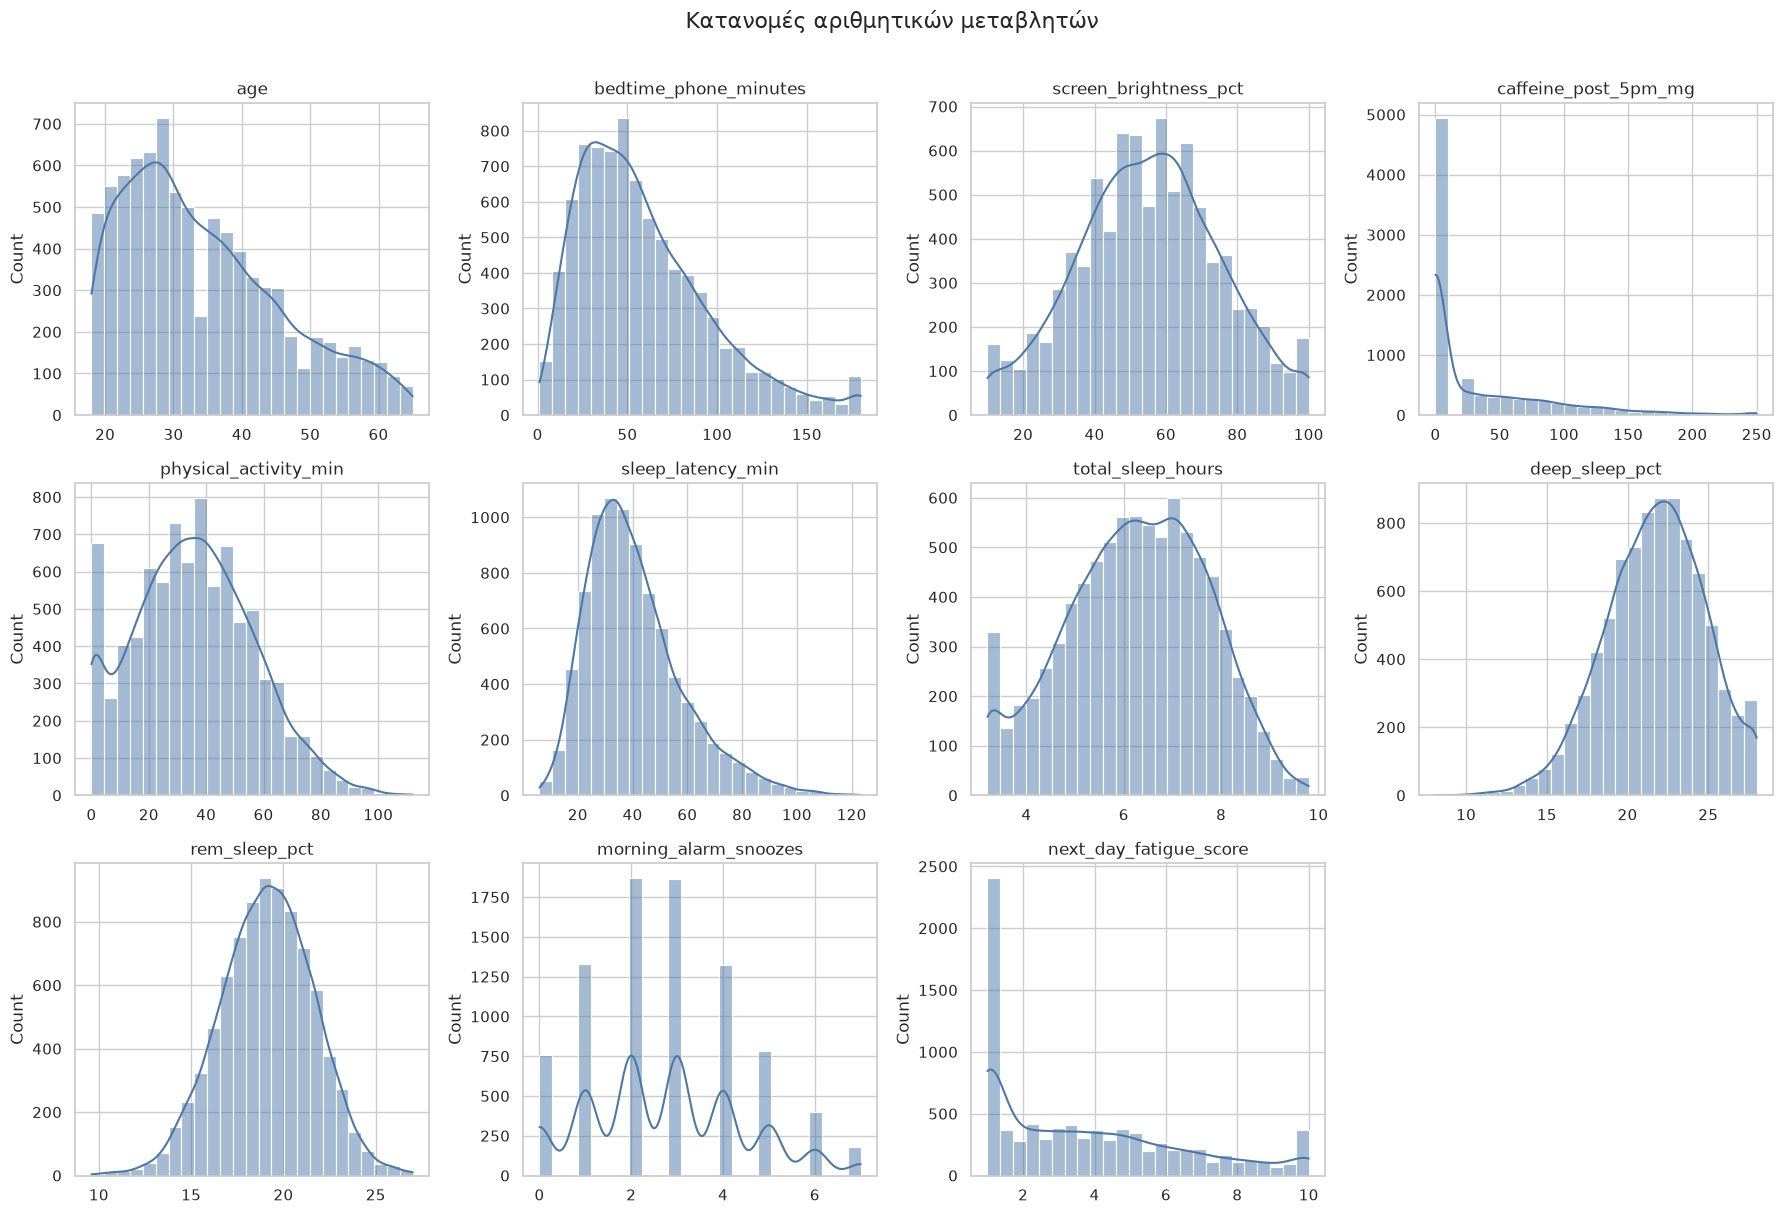

In [4]:
numeric_plot_cols = [
    c for c in df.select_dtypes(include='number').columns
    if c != 'blue_light_filter_active'
]

fig, axes = plt.subplots(3, 4, figsize=(18, 12))
axes = axes.flatten()
for ax, col in zip(axes, numeric_plot_cols):
    sns.histplot(df[col], bins=25, kde=True, ax=ax, color='#4C78A8')
    ax.set_title(col)
    ax.set_xlabel('')
for ax in axes[len(numeric_plot_cols):]:
    ax.axis('off')
plt.suptitle('Κατανομές αριθμητικών μεταβλητών', fontsize=16, y=1.01)
plt.tight_layout()
plt.show()

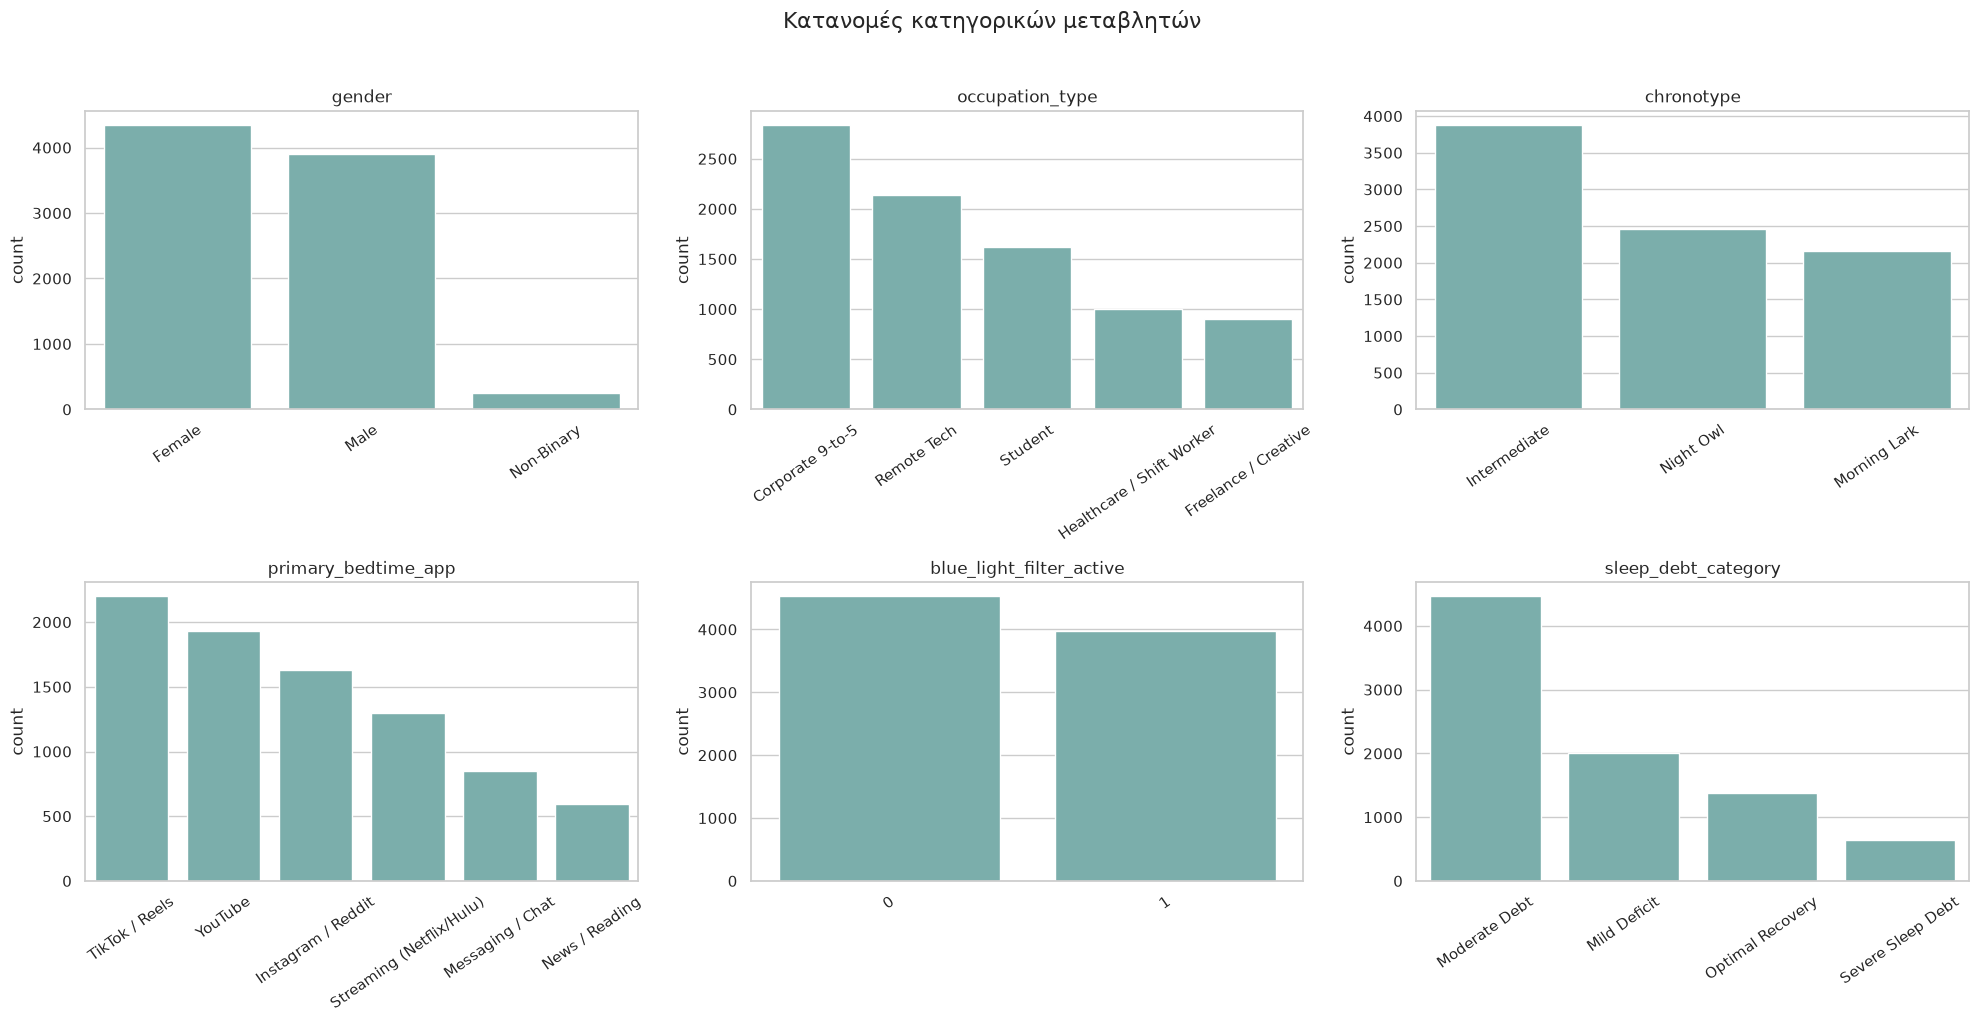

In [5]:
categorical_plot_cols = [
    'gender',
    'occupation_type',
    'chronotype',
    'primary_bedtime_app',
    'blue_light_filter_active',
    'sleep_debt_category',
]

fig, axes = plt.subplots(2, 3, figsize=(20, 10))
for ax, col in zip(axes.flatten(), categorical_plot_cols):
    order = df[col].value_counts().index
    sns.countplot(data=df, x=col, order=order, ax=ax, color='#72B7B2')
    ax.set_title(col)
    ax.set_xlabel('')
    ax.tick_params(axis='x', rotation=35)
plt.suptitle('Κατανομές κατηγορικών μεταβλητών', fontsize=16, y=1.02)
plt.tight_layout()
plt.show()

# Μέρος I – Ταξινόμηση της έλλειψης ύπνου

## Έλεγχος ισορροπίας κλάσεων

In [6]:
class_counts = df['sleep_debt_category'].value_counts()
class_percent = df['sleep_debt_category'].value_counts(normalize=True).mul(100)
class_table = pd.DataFrame({'Πλήθος': class_counts, 'Ποσοστό (%)': class_percent})
display(class_table)

,Πλήθος,Ποσοστό (%)
sleep_debt_category,,
Moderate Debt,4462,52.4941
Mild Deficit,2004,23.5765
Optimal Recovery,1387,16.3176
Severe Sleep Debt,647,7.6118


Ερώτηση: Υπάρχει πρόβλημα μη ισορροπημένων κλάσεων;

Απάντηση: Ναι. Η μεγαλύτερη κλάση είναι η Moderate Debt με 52,5%, ενώ η μικρότερη είναι η Severe Sleep Debt με 7,6%. Η αναλογία τους είναι περίπου 6,9 προς 1, άρα το dataset είναι μη ισορροπημένο. Για αυτό δεν βασίζομαι μόνο στο Accuracy και χρησιμοποιώ επίσης Balanced Accuracy και macro μετρικές.

## One-Hot Encoding και μετατροπή σε Arrays

In [7]:
classification_df = df.drop(columns=['user_id', 'next_day_fatigue_score'])
X_cls_df = classification_df.drop(columns=['sleep_debt_category'])
y_cls = classification_df['sleep_debt_category'].to_numpy()

categorical_cls = X_cls_df.select_dtypes(exclude='number').columns.tolist()
numeric_cls = X_cls_df.select_dtypes(include='number').columns.tolist()

X_cls_encoded = pd.get_dummies(
    X_cls_df,
    columns=categorical_cls,
    drop_first=False,
    dtype=int,
)
numeric_idx_cls = [X_cls_encoded.columns.get_loc(c) for c in numeric_cls]
X_cls = X_cls_encoded.to_numpy(dtype=float)

print('Αρχικά χαρακτηριστικά:', X_cls_df.shape[1])
print('Χαρακτηριστικά μετά το One-Hot Encoding:', X_cls.shape[1])
print('X:', X_cls.shape, '| y:', y_cls.shape)
X_cls_encoded.head()

Αρχικά χαρακτηριστικά: 15
Χαρακτηριστικά μετά το One-Hot Encoding: 28
X: (8500, 28) | y: (8500,)


,age,bedtime_phone_minutes,screen_brightness_pct,blue_light_filter_active,caffeine_post_5pm_mg,physical_activity_min,sleep_latency_min,total_sleep_hours,deep_sleep_pct,rem_sleep_pct,morning_alarm_snoozes,gender_Female,gender_Male,gender_Non-Binary,occupation_type_Corporate 9-to-5,occupation_type_Freelance / Creative,occupation_type_Healthcare / Shift Worker,occupation_type_Remote Tech,occupation_type_Student,chronotype_Intermediate,chronotype_Morning Lark,chronotype_Night Owl,primary_bedtime_app_Instagram / Reddit,primary_bedtime_app_Messaging / Chat,primary_bedtime_app_News / Reading,primary_bedtime_app_Streaming (Netflix/Hulu),primary_bedtime_app_TikTok / Reels,primary_bedtime_app_YouTube
0,29,179,54,1,0,21,84.4000,3.2000,23.5000,22.2000,7,1,0,0,0,0,1,0,0,1,0,0,1,0,0,0,0,0
1,58,163,76,1,92,72,86.7000,4.0600,18.0000,21.5000,7,1,0,0,0,0,0,0,1,1,0,0,0,0,0,0,0,1
2,41,100,59,0,45,23,70.5000,3.2000,18.1000,20.5000,7,1,0,0,0,0,1,0,0,0,0,1,0,0,0,0,1,0
3,36,34,52,0,97,49,38.1000,6.9900,21.6000,22.4000,1,0,0,1,0,0,0,1,0,1,0,0,0,0,0,0,0,1
4,23,27,82,1,0,38,32.3000,4.5800,24.1000,22.8000,4,1,0,0,0,0,1,0,0,1,0,0,0,0,0,0,1,0


## Train-Validation-Test 70-20-10

In [8]:
seed = 0

X_cls_dev, X_cls_test, y_cls_dev, y_cls_test = train_test_split(
    X_cls,
    y_cls,
    test_size=0.10,
    random_state=seed,
    stratify=y_cls,
)
X_cls_train, X_cls_valid, y_cls_train, y_cls_valid = train_test_split(
    X_cls_dev,
    y_cls_dev,
    test_size=2/9,
    random_state=seed,
    stratify=y_cls_dev,
)

print('Train:', X_cls_train.shape[0])
print('Validation:', X_cls_valid.shape[0])
print('Test:', X_cls_test.shape[0])

Train: 5950
Validation: 1700
Test: 850


## Z-Normalization

In [9]:
X_cls_train_scaled = X_cls_train.copy()
X_cls_valid_scaled = X_cls_valid.copy()

scaler_cls = StandardScaler()
X_cls_train_scaled[:, numeric_idx_cls] = scaler_cls.fit_transform(
    X_cls_train[:, numeric_idx_cls]
)
X_cls_valid_scaled[:, numeric_idx_cls] = scaler_cls.transform(
    X_cls_valid[:, numeric_idx_cls]
)

print('Ο scaler έγινε fit μόνο στο train set.')

Ο scaler έγινε fit μόνο στο train set.


## Βοηθητικές συναρτήσεις αξιολόγησης

In [10]:
def classification_metrics(y_true, y_pred):
    return {
        'Accuracy': accuracy_score(y_true, y_pred),
        'Precision': precision_score(y_true, y_pred, average='macro', zero_division=0),
        'Recall': recall_score(y_true, y_pred, average='macro', zero_division=0),
        'F1': f1_score(y_true, y_pred, average='macro', zero_division=0),
        'Balanced Accuracy': balanced_accuracy_score(y_true, y_pred),
    }


def make_classifier_pipeline(numeric_indices, *, n_neighbors=5, weights='uniform', parallel=False):
    # Στο CV ο scaler πρέπει να γίνεται fit ξανά μόνο στο train μέρος κάθε fold.
    preprocessing = ColumnTransformer(
        [('scale_numeric', StandardScaler(), numeric_indices)],
        remainder='passthrough',
    )
    model = KNeighborsClassifier(
        n_neighbors=n_neighbors,
        weights=weights,
        metric='euclidean',
        algorithm='brute',
        n_jobs=-1 if parallel else 1,
    )
    return Pipeline([('preprocessing', preprocessing), ('knn', model)])


def ci95(values):
    values = np.asarray(values, dtype=float)
    mean = values.mean()
    if len(values) < 2 or np.isclose(values.std(ddof=1), 0):
        return mean, mean
    margin = stats.t.ppf(0.975, df=len(values) - 1) * stats.sem(values)
    return mean - margin, mean + margin

## Επιλογή KNN με Train-Validation

In [11]:
sqrt_k_cls = int(np.sqrt(len(X_cls_train)))
k_values_cls = sorted(set([3, 5, 15, 50, sqrt_k_cls]))
print('N train =', len(X_cls_train), '| floor(√N) =', sqrt_k_cls)

classification_holdout_rows = []
classification_models = {}

for k in k_values_cls:
    for weights in ['uniform', 'distance']:
        model = KNeighborsClassifier(
            n_neighbors=k,
            weights=weights,
            metric='euclidean',
            algorithm='brute',
            n_jobs=-1,
        )
        model.fit(X_cls_train_scaled, y_cls_train)
        classification_models[(k, weights)] = model

        for split_name, X_split, y_split in [
            ('Train', X_cls_train_scaled, y_cls_train),
            ('Validation', X_cls_valid_scaled, y_cls_valid),
        ]:
            row = {'k': k, 'weights': weights, 'Set': split_name}
            row.update(classification_metrics(y_split, model.predict(X_split)))
            classification_holdout_rows.append(row)

classification_holdout = pd.DataFrame(classification_holdout_rows)
classification_holdout.round(4)

N train = 5950 | floor(√N) = 77


,k,weights,Set,Accuracy,Precision,Recall,F1,Balanced Accuracy
0,3,uniform,Train,0.8798,0.8801,0.8391,0.8571,0.8391
1,3,uniform,Validation,0.7629,0.7441,0.7105,0.7249,0.7105
2,3,distance,Train,1.0000,1.0000,1.0000,1.0000,1.0000
3,3,distance,Validation,0.7571,0.7346,0.7036,0.7177,0.7036
4,5,uniform,Train,0.8608,0.8689,0.8134,0.8370,0.8134
5,5,uniform,Validation,0.7841,0.7813,0.7233,0.7468,0.7233
6,5,distance,Train,1.0000,1.0000,1.0000,1.0000,1.0000
7,5,distance,Validation,0.7794,0.7668,0.7192,0.7397,0.7192
8,15,uniform,Train,0.8387,0.8550,0.7717,0.8045,0.7717
9,15,uniform,Validation,0.8024,0.8097,0.7311,0.7610,0.7311


In [12]:
classification_validation = classification_holdout[
    classification_holdout['Set'] == 'Validation'
].sort_values(['Balanced Accuracy', 'F1'], ascending=False)

best_cls_k = int(classification_validation.iloc[0]['k'])
best_cls_weights = classification_validation.iloc[0]['weights']
best_cls_selection_model = classification_models[(best_cls_k, best_cls_weights)]

display(classification_validation.round(4))

,k,weights,Set,Accuracy,Precision,Recall,F1,Balanced Accuracy
15,50,distance,Validation,0.8182,0.8380,0.7319,0.7711,0.7319
9,15,uniform,Validation,0.8024,0.8097,0.7311,0.7610,0.7311
13,50,uniform,Validation,0.8165,0.8389,0.7298,0.7689,0.7298
11,15,distance,Validation,0.7976,0.7991,0.7262,0.7555,0.7262
5,5,uniform,Validation,0.7841,0.7813,0.7233,0.7468,0.7233
19,77,distance,Validation,0.8124,0.8389,0.7200,0.7619,0.7200
7,5,distance,Validation,0.7794,0.7668,0.7192,0.7397,0.7192
17,77,uniform,Validation,0.8100,0.8389,0.7151,0.7575,0.7151
1,3,uniform,Validation,0.7629,0.7441,0.7105,0.7249,0.7105
3,3,distance,Validation,0.7571,0.7346,0.7036,0.7177,0.7036


Ερώτηση: Ποιος είναι ο καλύτερος συνδυασμός παραμέτρων;

Απάντηση: Ο καλύτερος συνδυασμός είναι k=50 με weights=distance. Στο validation έχει Balanced Accuracy 0,732 και macro F1 0,771. Επέλεξα τον συνδυασμό με βάση το Balanced Accuracy, επειδή οι κλάσεις δεν είναι ισορροπημένες. Με weights=distance το train score γίνεται 100%, επειδή κάθε δείγμα έχει τον εαυτό του ως γείτονα με απόσταση 0. Για αυτό η επιλογή βασίζεται στο validation και όχι στο train.

(Δεν έβαλα k=N με κείμενο σαν να το έχει γράψει μεθυσμένος αυτή τη φορά.)

## Τελική αξιολόγηση στο Test Set

In [13]:
X_cls_dev_scaled = X_cls_dev.copy()
X_cls_test_scaled = X_cls_test.copy()

scaler_cls_final = StandardScaler()
X_cls_dev_scaled[:, numeric_idx_cls] = scaler_cls_final.fit_transform(
    X_cls_dev[:, numeric_idx_cls]
)
X_cls_test_scaled[:, numeric_idx_cls] = scaler_cls_final.transform(
    X_cls_test[:, numeric_idx_cls]
)

best_cls_final_model = KNeighborsClassifier(
    n_neighbors=best_cls_k,
    weights=best_cls_weights,
    metric='euclidean',
    algorithm='brute',
    n_jobs=-1,
)
best_cls_final_model.fit(X_cls_dev_scaled, y_cls_dev)

classification_comparison = []
for set_name, model, X_split, y_split in [
    ('Train', best_cls_selection_model, X_cls_train_scaled, y_cls_train),
    ('Validation', best_cls_selection_model, X_cls_valid_scaled, y_cls_valid),
    ('Train + Validation', best_cls_final_model, X_cls_dev_scaled, y_cls_dev),
    ('Test', best_cls_final_model, X_cls_test_scaled, y_cls_test),
]:
    row = {'Set': set_name}
    row.update(classification_metrics(y_split, model.predict(X_split)))
    classification_comparison.append(row)

classification_comparison = pd.DataFrame(classification_comparison).set_index('Set')
display(classification_comparison.round(4))

,Accuracy,Precision,Recall,F1,Balanced Accuracy
Set,,,,,
Train,1.0000,1.0000,1.0000,1.0000,1.0000
Validation,0.8182,0.8380,0.7319,0.7711,0.7319
Train + Validation,1.0000,1.0000,1.0000,1.0000,1.0000
Test,0.8141,0.8565,0.7266,0.7716,0.7266


Ερώτηση: Πώς συγκρίνονται οι αξιολογήσεις στα train-validation-test;

Απάντηση: Στο test set η Balanced Accuracy είναι 0,727, σχεδόν ίδια με το 0,732 του validation. Η διαφορά είναι περίπου 0,005, άρα η απόδοση στο validation γενικεύεται παρόμοια στο test. Το τέλειο train score με weights=distance δεν σημαίνει ότι το μοντέλο προβλέπει τέλεια νέα δεδομένα.

## Holdout + 5-Fold Cross-Validation

In [14]:
cv_k_cls = int(np.sqrt(len(X_cls_dev)))
cv_k_values_cls = sorted(set([3, 5, 15, 50, cv_k_cls]))

classification_scoring = {
    'accuracy': 'accuracy',
    'precision': 'precision_macro',
    'recall': 'recall_macro',
    'f1': 'f1_macro',
    'balanced_accuracy': 'balanced_accuracy',
}

print('CV Train:', len(X_cls_dev), '| Test:', len(X_cls_test))

classification_grid = GridSearchCV(
    estimator=make_classifier_pipeline(numeric_idx_cls),
    param_grid={
        'knn__n_neighbors': cv_k_values_cls,
        'knn__weights': ['uniform', 'distance'],
    },
    scoring=classification_scoring,
    refit='balanced_accuracy',
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=seed),
    n_jobs=-1,
    return_train_score=False,
)
classification_grid.fit(X_cls_dev, y_cls_dev)

classification_cv_results = pd.DataFrame({
    'k': classification_grid.cv_results_['param_knn__n_neighbors'].astype(int),
    'weights': classification_grid.cv_results_['param_knn__weights'],
    'Accuracy': classification_grid.cv_results_['mean_test_accuracy'],
    'Precision': classification_grid.cv_results_['mean_test_precision'],
    'Recall': classification_grid.cv_results_['mean_test_recall'],
    'F1': classification_grid.cv_results_['mean_test_f1'],
    'Balanced Accuracy': classification_grid.cv_results_['mean_test_balanced_accuracy'],
}).sort_values(['Balanced Accuracy', 'F1'], ascending=False)

display(classification_cv_results.round(4))
print('Καλύτερες παράμετροι:', classification_grid.best_params_)

CV Train: 7650 | Test: 850


,k,weights,Accuracy,Precision,Recall,F1,Balanced Accuracy
4,15,uniform,0.8042,0.8193,0.7268,0.7612,0.7268
5,15,distance,0.8021,0.8147,0.7237,0.7585,0.7237
7,50,distance,0.8154,0.8407,0.7209,0.7630,0.7209
2,5,uniform,0.7860,0.7927,0.7179,0.7472,0.7179
6,50,uniform,0.8133,0.8424,0.7134,0.7567,0.7134
3,5,distance,0.7783,0.7767,0.7106,0.7374,0.7106
0,3,uniform,0.7703,0.7652,0.7056,0.7293,0.7056
9,87,distance,0.8056,0.8417,0.6962,0.7427,0.6962
8,87,uniform,0.8052,0.8415,0.6945,0.7411,0.6945
1,3,distance,0.7599,0.7498,0.6943,0.7170,0.6943


Καλύτερες παράμετροι: {'knn__n_neighbors': 15, 'knn__weights': 'uniform'}


In [15]:
best_idx = classification_grid.best_index_
classification_ci_rows = []

for metric_key, metric_label in [
    ('accuracy', 'Accuracy'),
    ('precision', 'Precision'),
    ('recall', 'Recall'),
    ('f1', 'F1'),
    ('balanced_accuracy', 'Balanced Accuracy'),
]:
    fold_values = [
        classification_grid.cv_results_[f'split{i}_test_{metric_key}'][best_idx]
        for i in range(5)
    ]
    lower, upper = ci95(fold_values)
    classification_ci_rows.append({
        'Μετρική': metric_label,
        'Μέσος όρος': np.mean(fold_values),
        'Κάτω 95% CI': lower,
        'Άνω 95% CI': upper,
    })

classification_ci = pd.DataFrame(classification_ci_rows).set_index('Μετρική')
display(classification_ci.round(4))

classification_cv_test = pd.DataFrame([
    classification_metrics(y_cls_test, classification_grid.predict(X_cls_test))
], index=['Test'])
display(classification_cv_test.round(4))

,Μέσος όρος,Κάτω 95% CI,Άνω 95% CI
Μετρική,,,
Accuracy,0.8042,0.7900,0.8184
Precision,0.8193,0.8035,0.8351
Recall,0.7268,0.7067,0.7470
F1,0.7612,0.7428,0.7797
Balanced Accuracy,0.7268,0.7067,0.7470


,Accuracy,Precision,Recall,F1,Balanced Accuracy
Test,0.8000,0.8280,0.7260,0.7636,0.7260


## Nested Cross-Validation με Outer 3-Fold και Inner 5-Fold

In [16]:
outer_cls = StratifiedKFold(n_splits=3, shuffle=True, random_state=seed)
nested_cls_rows = []

for fold, (outer_train_idx, outer_test_idx) in enumerate(
    outer_cls.split(X_cls_dev, y_cls_dev), start=1
):
    X_outer_train, X_outer_test = X_cls_dev[outer_train_idx], X_cls_dev[outer_test_idx]
    y_outer_train, y_outer_test = y_cls_dev[outer_train_idx], y_cls_dev[outer_test_idx]

    sqrt_k_outer = int(np.sqrt(len(X_outer_train)))
    k_values_outer = sorted(set([3, 5, 15, 50, sqrt_k_outer]))
    inner_grid = GridSearchCV(
        estimator=make_classifier_pipeline(numeric_idx_cls),
        param_grid={
            'knn__n_neighbors': k_values_outer,
            'knn__weights': ['uniform', 'distance'],
        },
        scoring='balanced_accuracy',
        refit=True,
        cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=seed + fold),
        n_jobs=-1,
    )
    inner_grid.fit(X_outer_train, y_outer_train)
    outer_pred = inner_grid.predict(X_outer_test)

    row = {
        'Outer Fold': fold,
        'Best k': inner_grid.best_params_['knn__n_neighbors'],
        'Best weights': inner_grid.best_params_['knn__weights'],
    }
    row.update(classification_metrics(y_outer_test, outer_pred))
    nested_cls_rows.append(row)

nested_classification = pd.DataFrame(nested_cls_rows).set_index('Outer Fold')
display(nested_classification.round(4))
display(pd.DataFrame({
    'Μέσος όρος': nested_classification[
        ['Accuracy', 'Precision', 'Recall', 'F1', 'Balanced Accuracy']
    ].mean(),
    'Τυπική απόκλιση': nested_classification[
        ['Accuracy', 'Precision', 'Recall', 'F1', 'Balanced Accuracy']
    ].std(ddof=1),
}).round(4))

,Best k,Best weights,Accuracy,Precision,Recall,F1,Balanced Accuracy
Outer Fold,,,,,,,
1,15,uniform,0.7957,0.8186,0.7088,0.7465,0.7088
2,15,uniform,0.8035,0.8216,0.7173,0.7553,0.7173
3,15,distance,0.8075,0.8124,0.7387,0.7691,0.7387


,Μέσος όρος,Τυπική απόκλιση
Accuracy,0.8022,0.0060
Precision,0.8175,0.0047
Recall,0.7216,0.0154
F1,0.7570,0.0114
Balanced Accuracy,0.7216,0.0154


In [17]:
# Μετά την αμερόληπτη outer-fold εκτίμηση, ξανακάνω την επιλογή
# υπερπαραμέτρων μόνο στο development set και αξιολογώ μία φορά στο test set.
nested_cls_final_search = GridSearchCV(
    estimator=make_classifier_pipeline(numeric_idx_cls),
    param_grid={
        'knn__n_neighbors': cv_k_values_cls,
        'knn__weights': ['uniform', 'distance'],
    },
    scoring='balanced_accuracy',
    refit=True,
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=seed),
    n_jobs=-1,
)
nested_cls_final_search.fit(X_cls_dev, y_cls_dev)

nested_classification_test = pd.DataFrame([
    classification_metrics(
        y_cls_test,
        nested_cls_final_search.predict(X_cls_test),
    )
], index=['Nested CV'])
display(nested_classification_test.round(4))
print('Τελικές παράμετροι Nested CV:', nested_cls_final_search.best_params_)

classification_test_comparison = pd.DataFrame([
    {'Μέθοδος': 'Extended Holdout', **classification_comparison.loc['Test'].to_dict()},
    {'Μέθοδος': '5-Fold CV', **classification_cv_test.loc['Test'].to_dict()},
    {'Μέθοδος': 'Nested CV', **nested_classification_test.loc['Nested CV'].to_dict()},
]).set_index('Μέθοδος')
display(classification_test_comparison.round(4))

,Accuracy,Precision,Recall,F1,Balanced Accuracy
Nested CV,0.8000,0.8280,0.7260,0.7636,0.7260


Τελικές παράμετροι Nested CV: {'knn__n_neighbors': 15, 'knn__weights': 'uniform'}


,Accuracy,Precision,Recall,F1,Balanced Accuracy
Μέθοδος,,,,,
Extended Holdout,0.8141,0.8565,0.7266,0.7716,0.7266
5-Fold CV,0.8000,0.8280,0.7260,0.7636,0.7260
Nested CV,0.8000,0.8280,0.7260,0.7636,0.7260


**Ερώτηση: Πώς συγκρίνονται οι τρεις μέθοδοι στο test set;**

**Απάντηση:** Τα αποτελέσματα είναι πολύ κοντά. Το 5-Fold CV και το Nested CV επιλέγουν τον ίδιο τελικό συνδυασμό παραμέτρων, γι' αυτό δίνουν τα ίδια test scores. Η μέση επίδοση των outer folds του Nested CV παραμένει η πιο αυστηρή εκτίμηση της γενίκευσης, ενώ το test set χρησιμοποιείται μόνο για την τελική σύγκριση.

# Μέρος II – Παλινδρόμηση του σκορ κούρασης

Στο Μέρος II αφαιρώ την κατηγορία έλλειψης ύπνου και χρησιμοποιώ ως στόχο το `next_day_fatigue_score`. Η επιλογή `stratify` δεν εφαρμόζεται σε συνεχή στόχο, οπότε οι διαχωρισμοί γίνονται με το ίδιο `seed=0` χωρίς stratification.

## Κατανομές μεταβλητών για την παλινδρόμηση

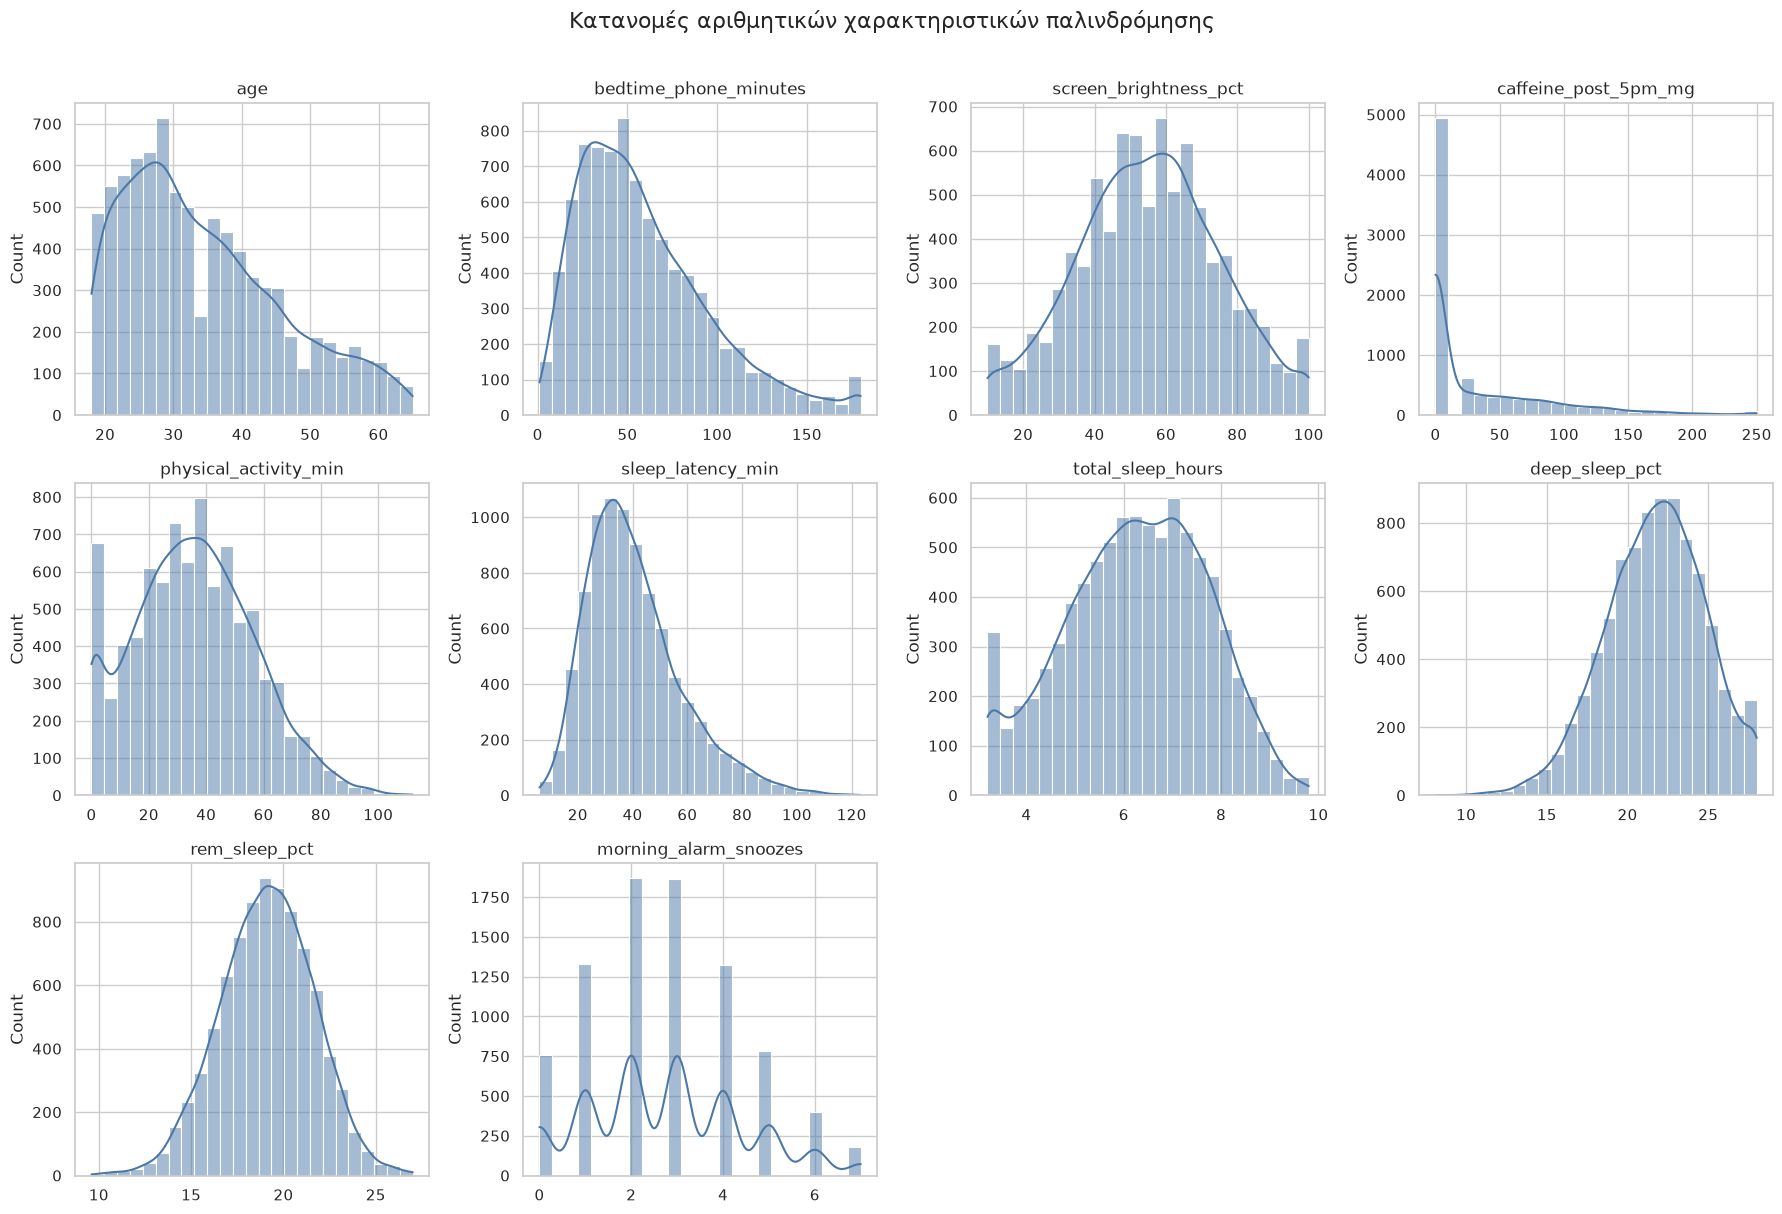

In [18]:
regression_plot_df = df.drop(columns=['user_id', 'sleep_debt_category'])
regression_numeric_features = [
    c for c in regression_plot_df.select_dtypes(include='number').columns
    if c not in ['blue_light_filter_active', 'next_day_fatigue_score']
]

fig, axes = plt.subplots(3, 4, figsize=(18, 12))
axes = axes.flatten()
for ax, col in zip(axes, regression_numeric_features):
    sns.histplot(regression_plot_df[col], bins=25, kde=True, ax=ax, color='#4C78A8')
    ax.set_title(col)
    ax.set_xlabel('')
for ax in axes[len(regression_numeric_features):]:
    ax.axis('off')
plt.suptitle('Κατανομές αριθμητικών χαρακτηριστικών παλινδρόμησης', fontsize=16, y=1.01)
plt.tight_layout()
plt.show()

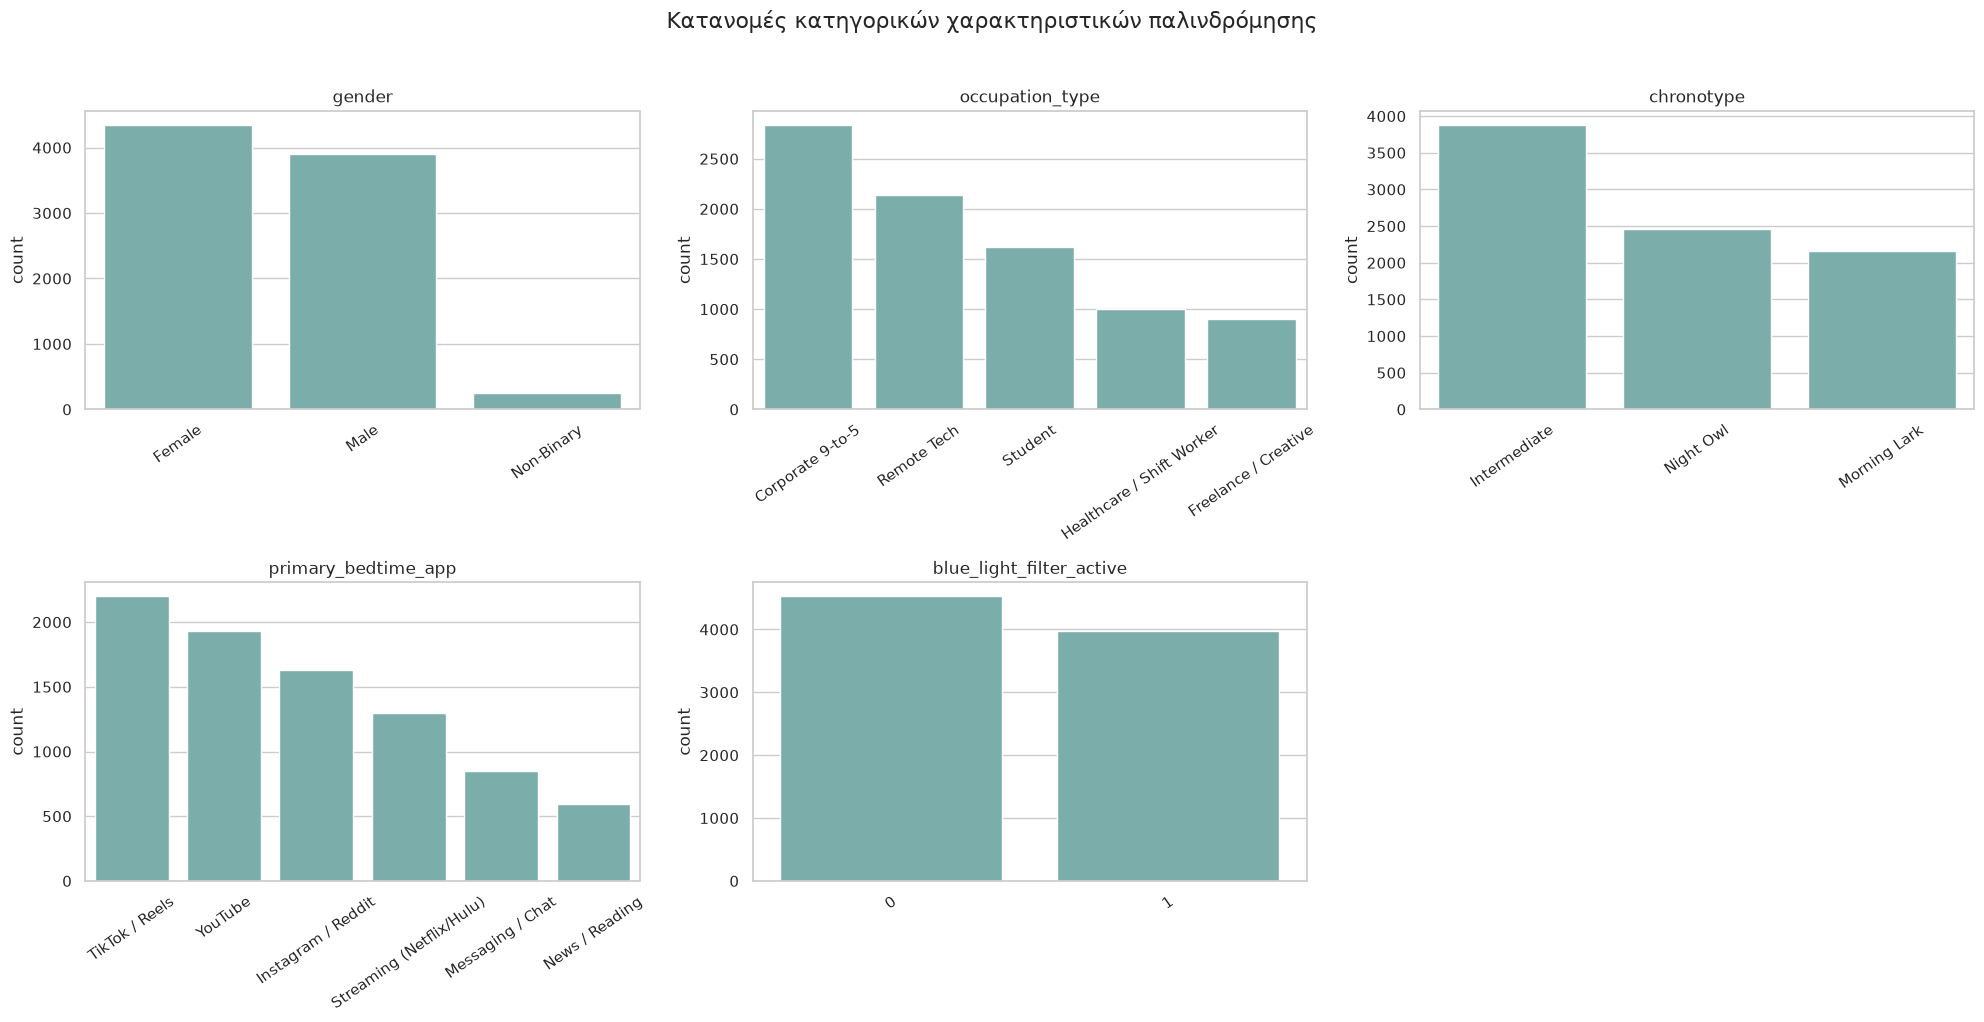

In [19]:
regression_categorical_features = [
    'gender',
    'occupation_type',
    'chronotype',
    'primary_bedtime_app',
    'blue_light_filter_active',
]

fig, axes = plt.subplots(2, 3, figsize=(20, 10))
for ax, col in zip(axes.flatten(), regression_categorical_features):
    order = regression_plot_df[col].value_counts().index
    sns.countplot(
        data=regression_plot_df,
        x=col,
        order=order,
        ax=ax,
        color='#72B7B2',
    )
    ax.set_title(col)
    ax.set_xlabel('')
    ax.tick_params(axis='x', rotation=35)
for ax in axes.flatten()[len(regression_categorical_features):]:
    ax.axis('off')
plt.suptitle('Κατανομές κατηγορικών χαρακτηριστικών παλινδρόμησης', fontsize=16, y=1.02)
plt.tight_layout()
plt.show()

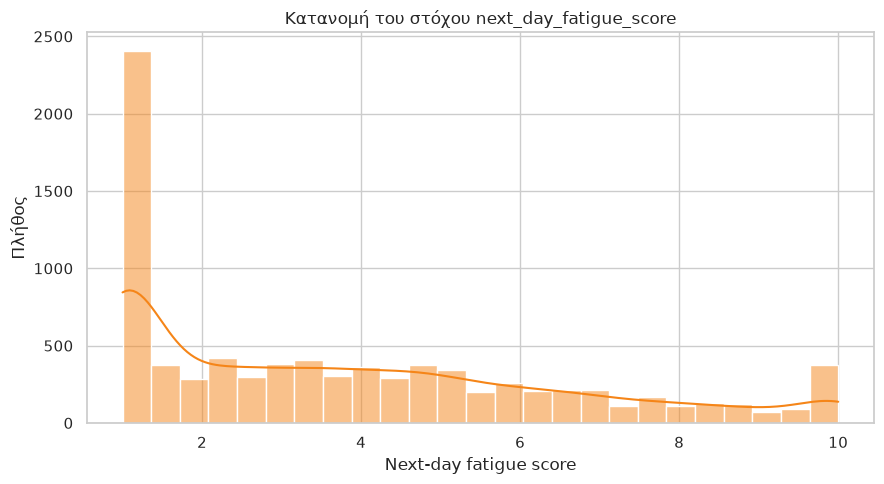

In [20]:
plt.figure(figsize=(9, 5))
sns.histplot(
    regression_plot_df['next_day_fatigue_score'],
    bins=25,
    kde=True,
    color='#F58518',
)
plt.title('Κατανομή του στόχου next_day_fatigue_score')
plt.xlabel('Next-day fatigue score')
plt.ylabel('Πλήθος')
plt.tight_layout()
plt.show()

Στην παλινδρόμηση ο στόχος `next_day_fatigue_score` είναι συνεχής μεταβλητή και όχι σύνολο κλάσεων. Επομένως, δεν υπάρχει έλεγχος ισορροπίας κλάσεων όπως στο Μέρος I. Η κατανομή του στόχου παρουσιάζει μεγαλύτερη συγκέντρωση στις χαμηλές τιμές και στα όρια της κλίμακας, κάτι που λαμβάνεται υπόψη με τη χρήση των MAE, RMSE και R².

## One-Hot Encoding και Train-Validation-Test 70-20-10

In [21]:
regression_df = df.drop(columns=['user_id', 'sleep_debt_category'])
X_reg_df = regression_df.drop(columns=['next_day_fatigue_score'])
y_reg = regression_df['next_day_fatigue_score'].to_numpy(dtype=float)

categorical_reg = X_reg_df.select_dtypes(exclude='number').columns.tolist()
numeric_reg = X_reg_df.select_dtypes(include='number').columns.tolist()

X_reg_encoded = pd.get_dummies(
    X_reg_df,
    columns=categorical_reg,
    drop_first=False,
    dtype=int,
)
numeric_idx_reg = [X_reg_encoded.columns.get_loc(c) for c in numeric_reg]
X_reg = X_reg_encoded.to_numpy(dtype=float)

X_reg_dev, X_reg_test, y_reg_dev, y_reg_test = train_test_split(
    X_reg,
    y_reg,
    test_size=0.10,
    random_state=seed,
)
X_reg_train, X_reg_valid, y_reg_train, y_reg_valid = train_test_split(
    X_reg_dev,
    y_reg_dev,
    test_size=2/9,
    random_state=seed,
)

print('X:', X_reg.shape, '| y:', y_reg.shape)
print('Train:', X_reg_train.shape[0])
print('Validation:', X_reg_valid.shape[0])
print('Test:', X_reg_test.shape[0])

X: (8500, 28) | y: (8500,)
Train: 5950
Validation: 1700
Test: 850


## Z-Normalization

In [22]:
X_reg_train_scaled = X_reg_train.copy()
X_reg_valid_scaled = X_reg_valid.copy()

scaler_reg = StandardScaler()
X_reg_train_scaled[:, numeric_idx_reg] = scaler_reg.fit_transform(
    X_reg_train[:, numeric_idx_reg]
)
X_reg_valid_scaled[:, numeric_idx_reg] = scaler_reg.transform(
    X_reg_valid[:, numeric_idx_reg]
)

print('Ο scaler έγινε fit μόνο στο train set.')

Ο scaler έγινε fit μόνο στο train set.


## Βοηθητικές συναρτήσεις παλινδρόμησης

In [23]:
def rmse(y_true, y_pred):
    return float(np.sqrt(mean_squared_error(y_true, y_pred)))


def regression_metrics(y_true, y_pred):
    return {
        'MAE': mean_absolute_error(y_true, y_pred),
        'RMSE': rmse(y_true, y_pred),
        'R2': r2_score(y_true, y_pred),
    }


def make_regression_pipeline(numeric_indices, *, n_neighbors=5, weights='uniform', parallel=False):
    # Στο CV ο scaler πρέπει να γίνεται fit ξανά μόνο στο train μέρος κάθε fold.
    preprocessing = ColumnTransformer(
        [('scale_numeric', StandardScaler(), numeric_indices)],
        remainder='passthrough',
    )
    model = KNeighborsRegressor(
        n_neighbors=n_neighbors,
        weights=weights,
        metric='euclidean',
        algorithm='brute',
        n_jobs=-1 if parallel else 1,
    )
    return Pipeline([('preprocessing', preprocessing), ('knn', model)])


rmse_scorer = make_scorer(rmse, greater_is_better=False)

## Επιλογή KNN Regressor με Train-Validation

In [24]:
sqrt_k_reg = int(np.sqrt(len(X_reg_train)))
k_values_reg = sorted(set([3, 5, 15, 50, sqrt_k_reg]))
print('N train =', len(X_reg_train), '| floor(√N) =', sqrt_k_reg)

regression_holdout_rows = []
regression_models = {}

for k in k_values_reg:
    for weights in ['uniform', 'distance']:
        model = KNeighborsRegressor(
            n_neighbors=k,
            weights=weights,
            metric='euclidean',
            algorithm='brute',
            n_jobs=-1,
        )
        model.fit(X_reg_train_scaled, y_reg_train)
        regression_models[(k, weights)] = model

        for split_name, X_split, y_split in [
            ('Train', X_reg_train_scaled, y_reg_train),
            ('Validation', X_reg_valid_scaled, y_reg_valid),
        ]:
            row = {'k': k, 'weights': weights, 'Set': split_name}
            row.update(regression_metrics(y_split, model.predict(X_split)))
            regression_holdout_rows.append(row)

regression_holdout = pd.DataFrame(regression_holdout_rows)
regression_holdout.round(4)

N train = 5950 | floor(√N) = 77


,k,weights,Set,MAE,RMSE,R2
0,3,uniform,Train,0.4861,0.6700,0.9373
1,3,uniform,Validation,0.6605,0.9151,0.8854
2,3,distance,Train,0.0000,0.0000,1.0000
3,3,distance,Validation,0.6588,0.9126,0.8860
4,5,uniform,Train,0.5109,0.6962,0.9323
5,5,uniform,Validation,0.6227,0.8459,0.9021
6,5,distance,Train,0.0000,0.0000,1.0000
7,5,distance,Validation,0.6210,0.8443,0.9024
8,15,uniform,Train,0.5437,0.7155,0.9285
9,15,uniform,Validation,0.5842,0.7691,0.9190


In [25]:
regression_validation = regression_holdout[
    regression_holdout['Set'] == 'Validation'
].sort_values(['MAE', 'RMSE'], ascending=True)

best_reg_k = int(regression_validation.iloc[0]['k'])
best_reg_weights = regression_validation.iloc[0]['weights']
best_reg_selection_model = regression_models[(best_reg_k, best_reg_weights)]

display(regression_validation.round(4))

,k,weights,Set,MAE,RMSE,R2
11,15,distance,Validation,0.5808,0.7661,0.9197
9,15,uniform,Validation,0.5842,0.7691,0.9190
15,50,distance,Validation,0.6034,0.7798,0.9168
13,50,uniform,Validation,0.6068,0.7841,0.9158
19,77,distance,Validation,0.6206,0.8008,0.9122
7,5,distance,Validation,0.6210,0.8443,0.9024
5,5,uniform,Validation,0.6227,0.8459,0.9021
17,77,uniform,Validation,0.6251,0.8063,0.9110
3,3,distance,Validation,0.6588,0.9126,0.8860
1,3,uniform,Validation,0.6605,0.9151,0.8854


Ερώτηση: Ποιος είναι ο καλύτερος συνδυασμός για την παλινδρόμηση;

Απάντηση: Ο καλύτερος συνδυασμός είναι k=15 με weights=distance. Στο validation έχει MAE 0,581, RMSE 0,766 και R² 0,920. Η επιλογή έγινε με βάση το μικρότερο MAE. Με weights=distance το train error μηδενίζεται, επειδή κάθε δείγμα έχει τον εαυτό του ως γείτονα με απόσταση 0. Για αυτό συγκρίνω τους συνδυασμούς στο validation.

## Τελική αξιολόγηση παλινδρόμησης στο Test Set

In [26]:
X_reg_dev_scaled = X_reg_dev.copy()
X_reg_test_scaled = X_reg_test.copy()

scaler_reg_final = StandardScaler()
X_reg_dev_scaled[:, numeric_idx_reg] = scaler_reg_final.fit_transform(
    X_reg_dev[:, numeric_idx_reg]
)
X_reg_test_scaled[:, numeric_idx_reg] = scaler_reg_final.transform(
    X_reg_test[:, numeric_idx_reg]
)

best_reg_final_model = KNeighborsRegressor(
    n_neighbors=best_reg_k,
    weights=best_reg_weights,
    metric='euclidean',
    algorithm='brute',
    n_jobs=-1,
)
best_reg_final_model.fit(X_reg_dev_scaled, y_reg_dev)

regression_comparison = []
for set_name, model, X_split, y_split in [
    ('Train', best_reg_selection_model, X_reg_train_scaled, y_reg_train),
    ('Validation', best_reg_selection_model, X_reg_valid_scaled, y_reg_valid),
    ('Train + Validation', best_reg_final_model, X_reg_dev_scaled, y_reg_dev),
    ('Test', best_reg_final_model, X_reg_test_scaled, y_reg_test),
]:
    row = {'Set': set_name}
    row.update(regression_metrics(y_split, model.predict(X_split)))
    regression_comparison.append(row)

regression_comparison = pd.DataFrame(regression_comparison).set_index('Set')
display(regression_comparison.round(4))

,MAE,RMSE,R2
Set,,,
Train,0.0000,0.0000,1.0000
Validation,0.5808,0.7661,0.9197
Train + Validation,0.0000,0.0000,1.0000
Test,0.5732,0.7806,0.9174


Ερώτηση: Πώς συγκρίνονται τα αποτελέσματα παλινδρόμησης στα train-validation-test;

Απάντηση: Στο test set το MAE είναι 0,573 μονάδες κούρασης, ενώ στο validation είναι 0,581. Η διαφορά είναι περίπου 0,008, άρα το validation έδωσε καλή εκτίμηση της απόδοσης σε νέα δεδομένα. Το μηδενικό train error οφείλεται στα distance weights και δεν εμφανίζεται στο validation ή στο test.

## Holdout + 5-Fold Cross-Validation για παλινδρόμηση

In [27]:
cv_k_reg = int(np.sqrt(len(X_reg_dev)))
cv_k_values_reg = sorted(set([3, 5, 15, 50, cv_k_reg]))

regression_scoring = {
    'mae': 'neg_mean_absolute_error',
    'rmse': rmse_scorer,
    'r2': 'r2',
}

print('CV Train:', len(X_reg_dev), '| Test:', len(X_reg_test))

regression_grid = GridSearchCV(
    estimator=make_regression_pipeline(numeric_idx_reg),
    param_grid={
        'knn__n_neighbors': cv_k_values_reg,
        'knn__weights': ['uniform', 'distance'],
    },
    scoring=regression_scoring,
    refit='mae',
    cv=KFold(n_splits=5, shuffle=True, random_state=seed),
    n_jobs=-1,
    return_train_score=False,
)
regression_grid.fit(X_reg_dev, y_reg_dev)

regression_cv_results = pd.DataFrame({
    'k': regression_grid.cv_results_['param_knn__n_neighbors'].astype(int),
    'weights': regression_grid.cv_results_['param_knn__weights'],
    'MAE': -regression_grid.cv_results_['mean_test_mae'],
    'RMSE': -regression_grid.cv_results_['mean_test_rmse'],
    'R2': regression_grid.cv_results_['mean_test_r2'],
}).sort_values(['MAE', 'RMSE'], ascending=True)

display(regression_cv_results.round(4))
print('Καλύτερες παράμετροι:', regression_grid.best_params_)

CV Train: 7650 | Test: 850


,k,weights,MAE,RMSE,R2
5,15,distance,0.5869,0.7725,0.9170
4,15,uniform,0.5899,0.7756,0.9163
7,50,distance,0.6058,0.7848,0.9143
6,50,uniform,0.6097,0.7896,0.9132
3,5,distance,0.6208,0.8400,0.9018
2,5,uniform,0.6220,0.8416,0.9014
9,87,distance,0.6335,0.8149,0.9076
8,87,uniform,0.6387,0.8210,0.9062
1,3,distance,0.6674,0.9151,0.8835
0,3,uniform,0.6686,0.9166,0.8831


Καλύτερες παράμετροι: {'knn__n_neighbors': 15, 'knn__weights': 'distance'}


In [28]:
best_idx = regression_grid.best_index_
regression_ci_rows = []

for metric_key, metric_label, negate in [
    ('mae', 'MAE', True),
    ('rmse', 'RMSE', True),
    ('r2', 'R2', False),
]:
    fold_values = np.array([
        regression_grid.cv_results_[f'split{i}_test_{metric_key}'][best_idx]
        for i in range(5)
    ])
    if negate:
        fold_values = -fold_values
    lower, upper = ci95(fold_values)
    regression_ci_rows.append({
        'Μετρική': metric_label,
        'Μέσος όρος': fold_values.mean(),
        'Κάτω 95% CI': lower,
        'Άνω 95% CI': upper,
    })

regression_ci = pd.DataFrame(regression_ci_rows).set_index('Μετρική')
display(regression_ci.round(4))

regression_cv_test = pd.DataFrame([
    regression_metrics(y_reg_test, regression_grid.predict(X_reg_test))
], index=['Test'])
display(regression_cv_test.round(4))

,Μέσος όρος,Κάτω 95% CI,Άνω 95% CI
Μετρική,,,
MAE,0.5869,0.5664,0.6075
RMSE,0.7725,0.7488,0.7962
R2,0.9170,0.9121,0.9218


,MAE,RMSE,R2
Test,0.5732,0.7806,0.9174


## Nested Cross-Validation με Outer 3-Fold και Inner 5-Fold

In [29]:
outer_reg = KFold(n_splits=3, shuffle=True, random_state=seed)
nested_reg_rows = []

for fold, (outer_train_idx, outer_test_idx) in enumerate(
    outer_reg.split(X_reg_dev), start=1
):
    X_outer_train, X_outer_test = X_reg_dev[outer_train_idx], X_reg_dev[outer_test_idx]
    y_outer_train, y_outer_test = y_reg_dev[outer_train_idx], y_reg_dev[outer_test_idx]

    sqrt_k_outer = int(np.sqrt(len(X_outer_train)))
    k_values_outer = sorted(set([3, 5, 15, 50, sqrt_k_outer]))
    inner_grid = GridSearchCV(
        estimator=make_regression_pipeline(numeric_idx_reg),
        param_grid={
            'knn__n_neighbors': k_values_outer,
            'knn__weights': ['uniform', 'distance'],
        },
        scoring='neg_mean_absolute_error',
        refit=True,
        cv=KFold(n_splits=5, shuffle=True, random_state=seed + fold),
        n_jobs=-1,
    )
    inner_grid.fit(X_outer_train, y_outer_train)
    outer_pred = inner_grid.predict(X_outer_test)

    row = {
        'Outer Fold': fold,
        'Best k': inner_grid.best_params_['knn__n_neighbors'],
        'Best weights': inner_grid.best_params_['knn__weights'],
    }
    row.update(regression_metrics(y_outer_test, outer_pred))
    nested_reg_rows.append(row)

nested_regression = pd.DataFrame(nested_reg_rows).set_index('Outer Fold')
display(nested_regression.round(4))
display(pd.DataFrame({
    'Μέσος όρος': nested_regression[['MAE', 'RMSE', 'R2']].mean(),
    'Τυπική απόκλιση': nested_regression[['MAE', 'RMSE', 'R2']].std(ddof=1),
}).round(4))

,Best k,Best weights,MAE,RMSE,R2
Outer Fold,,,,,
1,15,distance,0.5862,0.7741,0.9177
2,15,distance,0.5828,0.7683,0.9177
3,15,distance,0.6053,0.7897,0.9124


,Μέσος όρος,Τυπική απόκλιση
MAE,0.5914,0.0121
RMSE,0.7774,0.0111
R2,0.9159,0.0031


In [30]:
# Τελικό refit μόνο στο development set και μία αξιολόγηση στο test set.
nested_reg_final_search = GridSearchCV(
    estimator=make_regression_pipeline(numeric_idx_reg),
    param_grid={
        'knn__n_neighbors': cv_k_values_reg,
        'knn__weights': ['uniform', 'distance'],
    },
    scoring='neg_mean_absolute_error',
    refit=True,
    cv=KFold(n_splits=5, shuffle=True, random_state=seed),
    n_jobs=-1,
)
nested_reg_final_search.fit(X_reg_dev, y_reg_dev)

nested_regression_test = pd.DataFrame([
    regression_metrics(
        y_reg_test,
        nested_reg_final_search.predict(X_reg_test),
    )
], index=['Nested CV'])
display(nested_regression_test.round(4))
print('Τελικές παράμετροι Nested CV:', nested_reg_final_search.best_params_)

regression_test_comparison = pd.DataFrame([
    {'Μέθοδος': 'Extended Holdout', **regression_comparison.loc['Test'].to_dict()},
    {'Μέθοδος': '5-Fold CV', **regression_cv_test.loc['Test'].to_dict()},
    {'Μέθοδος': 'Nested CV', **nested_regression_test.loc['Nested CV'].to_dict()},
]).set_index('Μέθοδος')
display(regression_test_comparison.round(4))

,MAE,RMSE,R2
Nested CV,0.5732,0.7806,0.9174


Τελικές παράμετροι Nested CV: {'knn__n_neighbors': 15, 'knn__weights': 'distance'}


,MAE,RMSE,R2
Μέθοδος,,,
Extended Holdout,0.5732,0.7806,0.9174
5-Fold CV,0.5732,0.7806,0.9174
Nested CV,0.5732,0.7806,0.9174


**Ερώτηση: Πώς συγκρίνονται οι τρεις μέθοδοι στο test set;**

**Απάντηση:** Στην παλινδρόμηση οι τρεις μέθοδοι δίνουν ακριβώς τα ίδια test metrics. Το 5-Fold CV και το Nested CV καταλήγουν στο ίδιο τελικό μοντέλο (`k=15`, `weights=distance`), ενώ το απλό train-validation-test είχε ήδη επιλέξει τον ίδιο συνδυασμό. Το Nested CV δεν βελτιώνει εδώ το τελικό test score, αλλά προσθέτει την ανεξάρτητη αξιολόγηση στα outer folds, ώστε να ελέγχεται πιο αυστηρά η διαδικασία επιλογής παραμέτρων.

# Συμπέρασμα

Οι τρεις μέθοδοι δίνουν παρόμοια αποτελέσματα στο ίδιο ανεξάρτητο test set. Το Nested CV παρέχει επιπλέον την αυστηρότερη outer-fold εκτίμηση, επειδή η επιλογή υπερπαραμέτρων γίνεται μόνο στο inner loop. Το test set δεν συμμετέχει ούτε στην εκπαίδευση ούτε στην επιλογή παραμέτρων και χρησιμοποιείται μόνο στο τέλος για τη μικρή σύγκριση των μεθόδων.

Στο συγκεκριμένο παράδειγμα, η απλή διαδικασία train-validation-test έδωσε οριακά καλύτερο αποτέλεσμα στην ταξινόμηση, ενώ στην παλινδρόμηση οι τρεις μέθοδοι κατέληξαν στο ίδιο τελικό μοντέλο και στα ίδια test αποτελέσματα. Αυτό δείχνει ότι η επιπλέον πολυπλοκότητα δεν εγγυάται πάντοτε καλύτερη τελική επίδοση.

Αν όμως συνεχίζαμε να κάνουμε αλλαγές στο μοντέλο κοιτάζοντας κάθε φορά το validation ή, ακόμη χειρότερα, το test, μετά από κάποιο σημείο οι αποφάσεις μας θα προσαρμόζονταν στα συγκεκριμένα δεδομένα. Τότε το test θα έπαυε να είναι πραγματικά ανεξάρτητο και η απόδοση σε νέα δεδομένα θα μπορούσε να χειροτερεύσει. Επομένως, η ιδανική πρακτική δεν είναι να επιλέγεται μηχανικά η απλούστερη ή η πιο σύνθετη μέθοδος, αλλά να επιτυγχάνεται ένας σωστός συνδυασμός ακρίβειας, αξιοπιστίας και υπολογιστικής πολυπλοκότητας.